In [1]:
import pandas as pd
#usado para gerar gráficos
import matplotlib.pyplot as plt 

In [2]:
demandas = pd.read_csv('demandas.csv', parse_dates=['data_inicio', 'data_fim'])
demandas.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   chamado_mascarado  383 non-null    str           
 1   cliente            383 non-null    str           
 2   sistema            383 non-null    str           
 3   descricao          383 non-null    str           
 4   tag                383 non-null    str           
 5   billable           383 non-null    str           
 6   data_inicio        383 non-null    datetime64[us]
 7   data_fim           383 non-null    datetime64[us]
 8   esforco_horas      383 non-null    float64       
 9   qtd_sessoes        383 non-null    int64         
dtypes: datetime64[us](2), float64(1), int64(1), str(6)
memory usage: 30.1 KB


In [3]:
#Resumo estatistico da coluna de esforco_horas
print(demandas['esforco_horas'].describe())
print()
print(demandas['esforco_horas'].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

count    383.000000
mean       2.997650
std        6.625075
min        0.050000
25%        0.585000
50%        1.410000
75%        3.055000
max       87.520000
Name: esforco_horas, dtype: float64

0.10     0.2920
0.25     0.5850
0.50     1.4100
0.75     3.0550
0.90     6.7240
0.95    10.0430
0.99    19.6564
Name: esforco_horas, dtype: float64


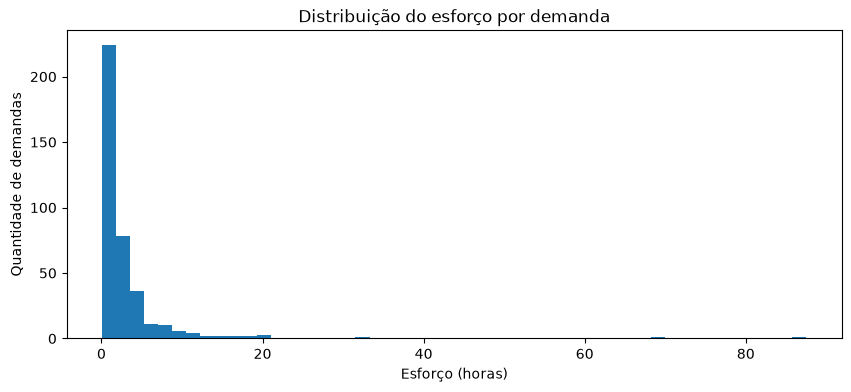

In [4]:
plt.figure(figsize=(10, 4))
plt.hist(demandas['esforco_horas'], bins=50)
plt.xlabel('Esforço (horas)')
plt.ylabel('Quantidade de demandas')
plt.title('Distribuição do esforço por demanda')
plt.show()

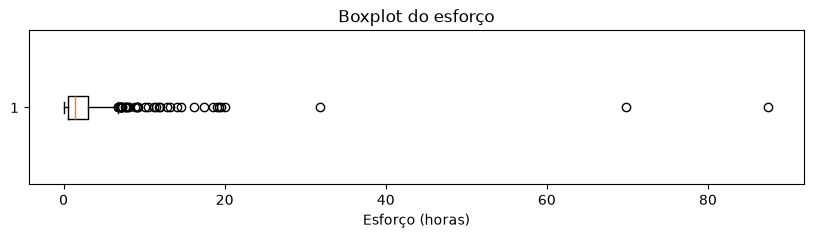

In [5]:
plt.figure(figsize=(10, 2))
plt.boxplot(demandas['esforco_horas'], orientation='horizontal')
plt.xlabel('Esforço (horas)')
plt.title('Boxplot do esforço')
plt.show()

In [6]:
import numpy as np

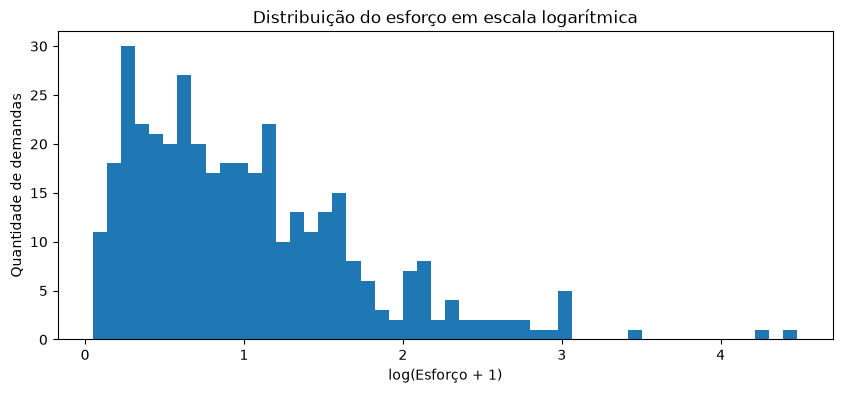

In [7]:
plt.figure(figsize=(10, 4))
plt.hist(np.log1p(demandas['esforco_horas']), bins=50)
plt.xlabel('log(Esforço + 1)')
plt.ylabel('Quantidade de demandas')
plt.title('Distribuição do esforço em escala logarítmica')
plt.show()

In [8]:
for piso in [0.1, 0.25, 0.5]:
    n = (demandas['esforco_horas'] < piso).sum()
    print(f"Abaixo de {piso}: {n} demandas ({n / len(demandas) * 100:.1f}%)")

Abaixo de 0.1: 4 demandas (1.0%)
Abaixo de 0.25: 28 demandas (7.3%)
Abaixo de 0.5: 81 demandas (21.1%)


In [9]:
for col in ['cliente', 'sistema', 'tag', 'billable']:
    print(demandas[col].value_counts(dropna=False))
    print()

cliente
Cliente_012    99
Cliente_025    46
Cliente_011    37
Cliente_022    26
Cliente_001    25
Cliente_008    19
Cliente_019    18
Cliente_005    17
Cliente_023    15
Cliente_024    14
Cliente_020    13
Cliente_009    10
Cliente_016     8
Cliente_021     6
Cliente_018     6
Cliente_007     5
Cliente_026     5
Cliente_014     3
Cliente_015     2
Cliente_017     2
Cliente_027     1
Cliente_002     1
Cliente_004     1
Cliente_013     1
Cliente_006     1
Cliente_003     1
Cliente_010     1
Name: count, dtype: int64

sistema
Sistema_006    315
Sistema_003     45
Sistema_001     20
Sistema_002      1
Sistema_005      1
Sistema_004      1
Name: count, dtype: int64

tag
Alteração                         184
Análise de problema                95
Nova Funcionalidade                85
Orçamento                          12
Analise de Ticket                   3
Alteração, Análise de problema      1
Sql/Update                          1
Documentação                        1
Relatório             

In [10]:
for col in ['sistema', 'tag', 'billable']:
    print(demandas.groupby(col)['esforco_horas'].agg(['count', 'mean', 'median']).sort_values('median', ascending=False))
    print()

             count      mean  median
sistema                             
Sistema_001     20  8.905000    3.44
Sistema_005      1  2.250000    2.25
Sistema_003     45  5.333333    1.84
Sistema_006    315  2.308540    1.19
Sistema_004      1  0.490000    0.49
Sistema_002      1  0.070000    0.07

                                count      mean  median
tag                                                    
Nova Funcionalidade                85  6.767059   3.410
Sql/Update                          1  2.250000   2.250
Documentação                        1  1.320000   1.320
Alteração                         184  2.069293   1.165
Análise de problema                95  1.796842   0.920
Orçamento                          12  1.036667   0.680
Alteração, Análise de problema      1  0.200000   0.200
Relatório                           1  0.180000   0.180
Analise de Ticket                   3  1.686667   0.130

          count      mean  median
billable                         
Yes          75  3

In [11]:
demandas[demandas['esforco_horas'] >= 50][['chamado_mascarado', 'cliente', 'sistema', 'tag', 'esforco_horas', 'qtd_sessoes', 'descricao']]

,chamado_mascarado,cliente,sistema,tag,esforco_horas,qtd_sessoes,descricao
141,Chamado_142,Cliente_012,Sistema_003,Nova Funcionalidade,69.86,56,Chamado_142 - Criação Power Bi Movidesk - Volt...
352,Chamado_353,Cliente_012,Sistema_001,Nova Funcionalidade,87.52,70,Chamado_353 - Projeto IBS BI
